# Work Flow to check that mesh nodes are ordered correctly for TaperSlip

In [7]:
# require libraries 
import numpy as np

# plotting using matplotlib 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

#plotting mesh 
import plotly.graph_objects as go

## subroutines used

In [2]:
def read_mesh_file(filepath):
    """Read the mesh file and return a list of quads (each quad is a list of 4 nodes)."""
    quads = []
    with open(filepath, 'r') as f:
        for line in f:
            values = list(map(float, line.strip().split()))
            quad = [tuple(values[i:i+3]) for i in range(0, len(values), 3)]
            quads.append(quad)
    return quads

def shallowest_node_index(quad):
    """Find the index of the shallowest node, and if tie, one with smallest longitude."""
    shallowest = sorted(enumerate(quad), key=lambda x: (x[1][2], x[1][1]))
    return shallowest[0][0]

def is_counter_clockwise(quad):
    """Check if the quad is ordered counter-clockwise in lat/lon space."""
    coords = np.array([[pt[1], pt[0]] for pt in quad])  # (lon, lat)
    sum = 0.0
    for i in range(len(coords)):
        x1, y1 = coords[i]
        x2, y2 = coords[(i + 1) % len(coords)]
        sum += (x2 - x1) * (y2 + y1)
    return sum < 0  # Negative sum means CCW

def reorder_quad(quad):
    """Reorder quad to start from shallowest (and smallest lon if tie), and go CCW."""
    index = shallowest_node_index(quad)
    rotated = quad[index:] + quad[:index]
    if not is_counter_clockwise(rotated):
        rotated = rotated[0:1] + rotated[1:][::-1]  # Keep first node, reverse the rest
    return rotated

def write_mesh_file(quads, filepath):
    """Write the reordered quads to a file."""
    with open(filepath, 'w') as f:
        for quad in quads:
            line = ' '.join(f"{lat:.6f} {lon:.6f} {depth:.2f}" for lat, lon, depth in quad)
            f.write(line + '\n')

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

def plot_quads_3d(quads):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    for quad in quads:
        # Extract x=lon, y=lat, z=-depth for better visual (deeper is lower)
        verts = [[(node[1], node[0], node[2]) for node in quad]]
        poly = Poly3DCollection(verts, alpha=0.6, edgecolor='k', facecolor='skyblue')
        ax.add_collection3d(poly)

    # Labeling
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_zlabel("Depth")
    ax.set_title("3D Quadrangle Mesh")

    # Adjust view
    ax.view_init(elev=30, azim=-135)
    plt.tight_layout()
    plt.show()

import plotly.graph_objects as go

def plot_quads_3d_plotly(quads):
    fig = go.Figure()

    for quad in quads:
        # Extract x=lon, y=lat, z=depth (flip sign so deeper = lower)
        x = [pt[1] for pt in quad] + [quad[0][1]]  # lon
        y = [pt[0] for pt in quad] + [quad[0][0]]  # lat
        z = [-pt[2] for pt in quad] + [-quad[0][2]]  # depth

        fig.add_trace(go.Scatter3d(
            x=x, y=y, z=z,
            mode='lines',
            line=dict(color='blue'),
            showlegend=False
        ))

        fig.add_trace(go.Mesh3d(
            x=x[:-1], y=y[:-1], z=z[:-1],
            color='skyblue',
            opacity=0.5,
            i=[0], j=[1], k=[2],  # dummy values to show as surface
            showscale=False,
            flatshading=True
        ))

    fig.update_layout(
        title="Interactive 3D Quadrangle Mesh",
        scene=dict(
            xaxis_title='Longitude',
            yaxis_title='Latitude',
            zaxis_title='Depth',
            zaxis=dict(autorange='reversed')  # So deeper is down
        ),
        margin=dict(l=0, r=0, b=0, t=40)
    )

    fig.show()


## Read in mesh file 

In [3]:
input_file = 'southamerica_quadrilateral_coors.dat'
quads = read_mesh_file(input_file)

Reorder mesh so that:
-  first node is the shallowest and if there are multiple choose the node with the smallest longitude
- reorder remaining nodes so tha they are ordered couter-clockwise


In [4]:
reordered_quads = [reorder_quad(quad) for quad in quads]


Plot new mesh:

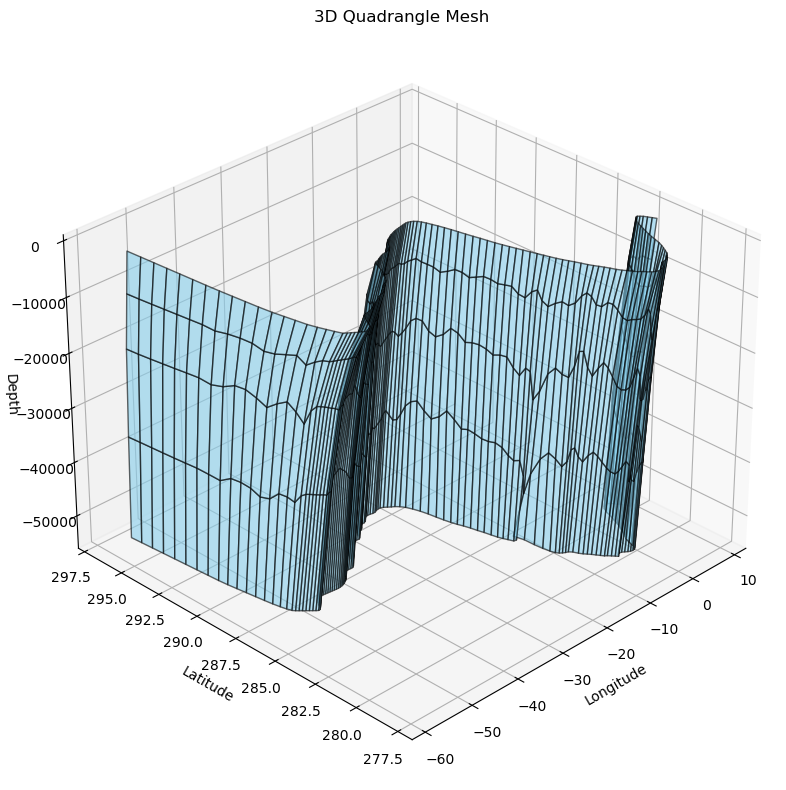

In [5]:
# Reuse the quads you already read and reordered
plot_quads_3d(reordered_quads)  # plotting reorded mesh using matplotlib

plot_quads_3d_plotly(reordered_quads)  # plotting reorded mesh using plotly (interactive) 

Write new mesh to file 

In [6]:
output_file = 'southamerica_quadrilateral_coors_reordered.dat'
write_mesh_file(reordered_quads, output_file)